# 🔬 Hybrid PINN - ANN + FEM (TensorFlow)

Ce notebook connecte un réseau de neurones à une fonction de simulation FEM (Picard) différentiable pour estimer D₀.

In [74]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

In [75]:
def build_ann_model(input_dim=4):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(16, activation='tanh'),
        Dense(16, activation='tanh'),
        Dense(1, activation='softplus')  # pour garantir D0 > 0
    ])
    return model

model = build_ann_model()
optimizer = Adam(learning_rate=0.001)  # Reduced learning rate

In [76]:
# 2. Input Normalization (Critical Fix)
X_mean = tf.constant([0.13, 20.0, 0.45, 0.6], dtype=tf.float32)
X_std = tf.constant([0.02, 5.0, 0.05, 0.05], dtype=tf.float32)

def normalize(x):
    return (x - X_mean) / X_std


In [86]:
@tf.function
def simulate_model_tf(Dv, S0, phi, rho_eau, dx, dt, Tmax, Nx):
    Nt = tf.cast(Tmax // dt, tf.int32)
    x_vals = tf.linspace(0.0, dx * tf.cast(Nx - 1, tf.float32), Nx)

    # 🔧 Paramètres physiques
    alpha0 = 0.005
    Sc = 0.8
    nShape = 5
    S_cap = 0.75
    beta = 2.5
    Pc0 = 5e6
    K_in = 1.7e-20
    eta_l = 1e-3

    # Initialisation avec très faible saturation partout sauf à gauche
    S = tf.ones((Nx,), dtype=tf.float32) * 0.01  # très faible
    S = tf.tensor_scatter_nd_update(S, [[0]], [S0])  # S0 = 0.6 à gauche


    M = tf.ones((Nx,), dtype=tf.float32) * dx
    M = tf.tensor_scatter_nd_update(M, [[0], [Nx-1]], [dx/2, dx/2])

    # 📈 Fonctions de diffusion
    def Dvapeur(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        fs = alpha0 + (1.0 - alpha0) / (1.0 + tf.pow((1.0 - S_val) / (1.0 - Sc), nShape))
        return tf.clip_by_value(fs, 1e-12, 10.0) * Dv

    def Dcapi(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        dpc = -beta * Pc0 * tf.pow(S_val, -beta - 1)
        return tf.abs(dpc) * K_in / eta_l

    def D_S(S_val):
        weight = tf.math.sigmoid(50.0 * (S_val - S_cap))
        return weight * Dcapi(S_val) + (1.0 - weight) * Dvapeur(S_val)

    # 🔁 Boucle temporelle
    for _ in tf.range(Nt):
        S_old = S
        for _ in tf.range(5):  # Picard simplifié
            D_vals = D_S(S)

            D_left = (D_vals[:-1] + D_vals[1:]) / 2.0
            fluxes = D_left * (S[1:] - S[:-1]) / dx

            dS_dt = tf.zeros_like(S)

            # 🌡️ Mise à jour des points intérieurs
            interior_flux = (fluxes[1:] - fluxes[:-1]) / dx
            dS_dt = tf.tensor_scatter_nd_add(
                dS_dt,
                tf.range(1, Nx-1)[:, tf.newaxis],
                interior_flux
            )

            # ⚠️ Bord droit : Neumann = 0  ⇒ flux sortant ≈ 0
            last_flux = fluxes[-1] / dx
            dS_dt = tf.tensor_scatter_nd_add(dS_dt, [[Nx-1]], [-last_flux])

            # 🔁 Mise à jour de S avec Euler explicite
            S = S_old + dt * dS_dt
            S = tf.tensor_scatter_nd_update(S, [[0]], [S0])  # Dirichlet à gauche

    w_final = phi * rho_eau * S
    return x_vals, w_final


In [78]:
@tf.function
# 4. Interpolation with Unit Conversion
def tf_linear_interp(x_known, y_known, x_interp):
    # Convert mm to meters for experimental data
    x_interp_m = x_interp * 1e-3 # Convert mm to m   
    indices = tf.searchsorted(x_known, x_interp_m, side='right') - 1
    indices = tf.clip_by_value(indices, 0, tf.shape(x_known)[0] - 2)
    x0 = tf.gather(x_known, indices)
    x1 = tf.gather(x_known, indices + 1)
    y0 = tf.gather(y_known, indices)
    y1 = tf.gather(y_known, indices + 1)
    return y0 + (y1 - y0) * (x_interp_m - x0) / (x1 - x0 + 1e-12)

In [79]:
x_known = tf.constant([0.0, 0.01, 0.02], dtype=tf.float32)  # en mètres
y_known = tf.constant([0.0, 1.0, 2.0], dtype=tf.float32)
x_interp = tf.constant([5.0, 10.0, 15.0], dtype=tf.float32)  # en mm

result = tf_linear_interp(x_known, y_known, x_interp)
print("Interpolated values:", result.numpy())


Interpolated values: [0.50000006 1.0000001  1.5000001 ]


In [80]:
# 1. Charger les données
df = pd.read_csv("w_exp_data.csv")
x_exp = tf.constant(df['x_mm'].values.astype(np.float32))       # En mm
w_exp = tf.constant(df['w_exp_72h'].values.astype(np.float32))  # En kg/m³

# 2. Normaliser uniquement pour la fonction de perte
w_exp_mean = tf.reduce_mean(w_exp)
w_exp_std = tf.math.reduce_std(w_exp)
w_exp_normalized = (w_exp - w_exp_mean) / w_exp_std   # ✅ pas de 1e-3 ici !


In [81]:
# ✅ compute_loss (sans stop_gradient sur l'interpolation)
def compute_loss(model, input_tensor, x_exp, w_exp_norm):
    normalized_input = normalize(input_tensor)
    D0 = model(normalized_input)
    Dv = tf.clip_by_value(tf.squeeze(D0), 1e-10, 1e-7)

    x_model, w_model = simulate_model_tf(
        Dv, 0.6, 0.119, 1000.0,
        dx=1e-3, dt=10.0, Tmax=72*3600, Nx=100
    )
    w_interp = tf_linear_interp(x_model, w_model, x_exp)
    # w_interp = tf.stop_gradient(w_interp)  # 🔧 ENLEVER cette ligne pour garder le lien gradient
    w_interp_norm = (w_interp - w_exp_mean) / w_exp_std

    return tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))

In [82]:
with tf.GradientTape() as tape:
    x = tf.convert_to_tensor([[0.119, 20.0, 0.45, 0.6]], dtype=tf.float32)
    x_norm = normalize(x)
    y = model(x_norm)
    loss = tf.reduce_mean((y - 1e-8)**2)  # simple MSE
grads = tape.gradient(loss, model.trainable_variables)
print([tf.reduce_max(tf.abs(g)).numpy() if g is not None else None for g in grads])


[np.float32(0.21529481), np.float32(0.39144534), np.float32(0.07582841), np.float32(0.2857211), np.float32(0.15564714), np.float32(0.542165)]


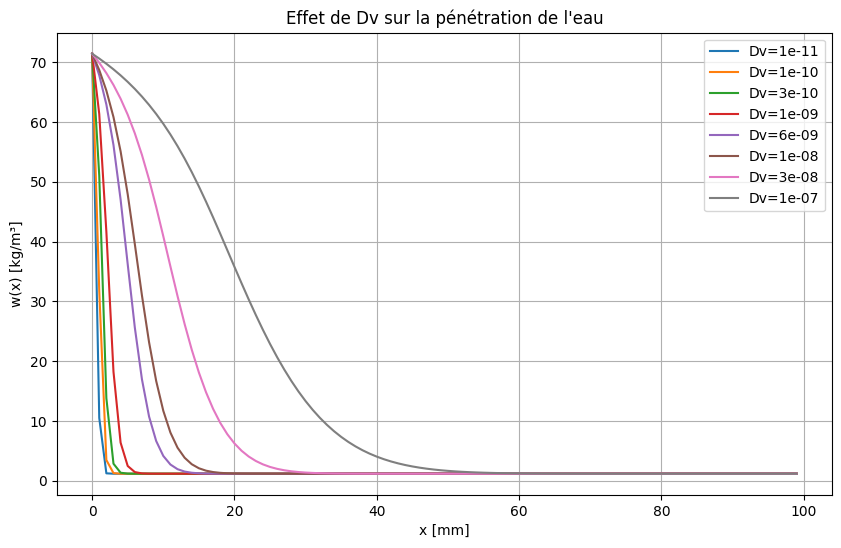

In [87]:
# Paramètres de simulation
dx = 1e-3  # 1 mm
dt = 100.0   # pas de temps réduit
Tmax = 72*3600  # 72 heures
Nx = 100

plt.figure(figsize=(10, 6))
for Dv_test in [1e-11, 1e-10, 3e-10, 1e-9, 6e-9, 1e-8, 3e-8, 1e-7]:
    x_model, w_model = simulate_model_tf(
        tf.constant(Dv_test, dtype=tf.float32),
        S0=0.6,
        phi=0.119,
        rho_eau=1000.0,
        dx=dx,
        dt=dt,
        Tmax=Tmax,
        Nx=Nx
    )
    plt.plot(x_model.numpy()*1000, w_model.numpy(), label=f"Dv={Dv_test:.0e}")

plt.xlabel("x [mm]")
plt.ylabel("w(x) [kg/m³]")
plt.title("Effet de Dv sur la pénétration de l'eau")
plt.legend()
plt.grid(True)
plt.show()

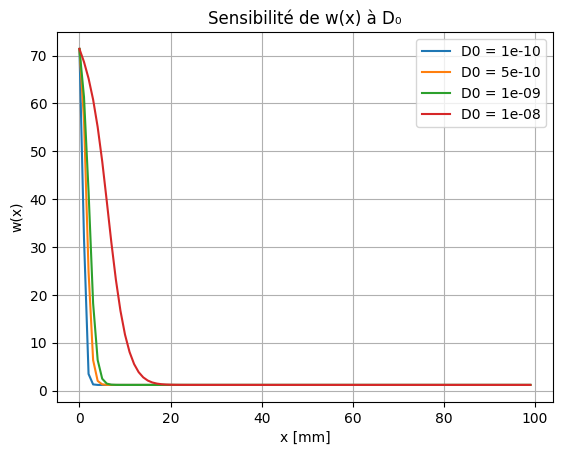

In [88]:
for D0_val in [1e-10, 5e-10, 1e-9, 1e-8]:
    x_sim, w_sim = simulate_model_tf(
        tf.constant(D0_val), 0.6, 0.119, 1000.0,
        dx=1e-3, dt=10.0, Tmax=72*3600, Nx=100
    )
    plt.plot(x_sim.numpy() * 1000, w_sim.numpy(), label=f"D0 = {D0_val:.0e}")
plt.legend()
plt.title("Sensibilité de w(x) à D₀")
plt.xlabel("x [mm]")
plt.ylabel("w(x)")
plt.grid(True)
plt.show()

🔹 D0 initial prédit : [[1.e-08]]
✅ Simulation réussie : w(x) shape = (150,)
🔹 Loss test = 1.6523827


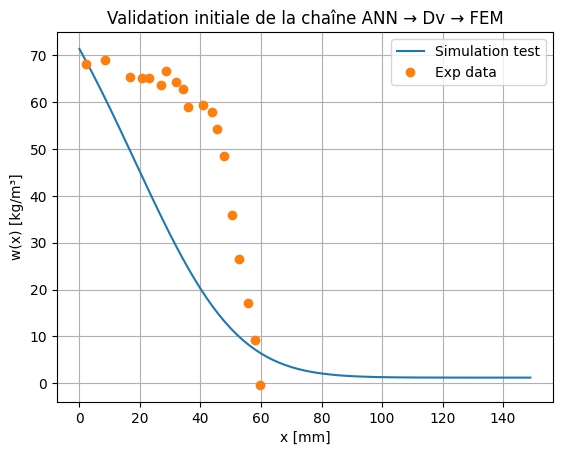

In [ ]:
# 🔍 Bloc de test avant entraînement
test_input = tf.convert_to_tensor([[0.119, 20.0, 0.45, 0.6]], dtype=tf.float32)
normalized_input = normalize(test_input)

# 1. Test du réseau de neurones
D0_pred = model(normalized_input)
D0_pred = tf.clip_by_value(D0_pred, 1e-12, 1e-8)  # Assure que D0 est positif
print("🔹 D0 initial prédit :", D0_pred.numpy())

# 2. Test du modèle physique avec Dv = D0_pred
try:
    x_model, w_model = simulate_model_tf(
        tf.squeeze(D0_pred), 0.6, 0.119, 1000.0,
        dx=1e-3, dt=10.0, Tmax=72*3600, Nx=150
    )
    print("✅ Simulation réussie : w(x) shape =", w_model.shape)

    # 3. Test du loss
    w_interp = tf_linear_interp(x_model, w_model, x_exp)
    w_interp_norm = (w_interp - w_exp_mean) / w_exp_std
    loss_test = tf.reduce_mean(tf.square(w_interp_norm - w_exp_normalized))
    print("🔹 Loss test =", loss_test.numpy())

    # 4. Sanity check graphique
    import matplotlib.pyplot as plt
    plt.plot(x_model.numpy()*1000, w_model.numpy(), label="Simulation test")
    plt.plot(x_exp.numpy(), w_exp.numpy(), 'o', label="Exp data")
    plt.xlabel("x [mm]")
    plt.ylabel("w(x) [kg/m³]")
    plt.title("Validation initiale de la chaîne ANN → Dv → FEM")
    plt.grid(True)
    plt.legend()
    plt.show()

except Exception as e:
    print("❌ Erreur dans la simulation ou le loss :", e)


In [ ]:
def simple_test():
    input_tensor = tf.convert_to_tensor([[0.119, 20.0, 0.45, 0.6]], dtype=tf.float32)
    input_norm = normalize(input_tensor)

    with tf.GradientTape() as tape:
        y = model(input_norm)
    grads = tape.gradient(y, model.trainable_variables)
    for i, g in enumerate(grads):
        print(f"Grad {i}:", tf.reduce_max(tf.abs(g)).numpy() if g is not None else None)

simple_test()


Grad 0: 0.14278017
Grad 1: 0.25960046
Grad 2: 0.08188275
Grad 3: 0.29556432
Grad 4: 0.18457733
Grad 5: 0.51606375


In [ ]:
input_tensor = tf.convert_to_tensor([[0.119, 20.0, 0.45, 0.6]], dtype=tf.float32)
loss_history = []
D0_history = []

# Training loop (réduit)
for epoch in range(10):
    with tf.GradientTape() as tape:
        normalized_input = normalize(input_tensor)
        D0_pred = model(normalized_input)
        loss = compute_loss(model, input_tensor, x_exp, w_exp_normalized)
    grads = tape.gradient(loss, model.trainable_variables)

    # Debug print: print tensors directly (do not use .numpy() before optimizer)
    print(f"Epoch {epoch}")
    print("  Loss (tensor):", loss)
    print("  Model output (tensor):", D0_pred)
    for i, (var, g) in enumerate(zip(model.trainable_variables, grads)):
        print(f"  Var {i} shape: {var.shape}, Grad {i} sum: {tf.reduce_sum(tf.abs(g)) if g is not None else 'None'}")

    grads = [tf.clip_by_value(g, -1.0, 1.0) if g is not None else None for g in grads]
    optimizer.apply_gradients(zip(grads, model.trainable_variables))

    # Track loss and D0 for visualization (convert to numpy only for storage)
    loss_history.append(loss.numpy())
    D0_val = D0_pred.numpy().squeeze()
    D0_history.append(D0_val)


Epoch 0
  Loss (tensor): tf.Tensor(0.6489828, shape=(), dtype=float32)
  Model output (tensor): tf.Tensor([[0.72580206]], shape=(1, 1), dtype=float32)
  Var 0 shape: (4, 16), Grad 0 sum: 0.0
  Var 1 shape: (16,), Grad 1 sum: 0.0
  Var 2 shape: (16, 16), Grad 2 sum: 0.0
  Var 3 shape: (16,), Grad 3 sum: 0.0
  Var 4 shape: (16, 1), Grad 4 sum: 0.0
  Var 5 shape: (1,), Grad 5 sum: 0.0
Epoch 1
  Loss (tensor): tf.Tensor(0.6489828, shape=(), dtype=float32)
  Model output (tensor): tf.Tensor([[0.72580206]], shape=(1, 1), dtype=float32)
  Var 0 shape: (4, 16), Grad 0 sum: 0.0
  Var 1 shape: (16,), Grad 1 sum: 0.0
  Var 2 shape: (16, 16), Grad 2 sum: 0.0
  Var 3 shape: (16,), Grad 3 sum: 0.0
  Var 4 shape: (16, 1), Grad 4 sum: 0.0
  Var 5 shape: (1,), Grad 5 sum: 0.0
Epoch 2
  Loss (tensor): tf.Tensor(0.6489828, shape=(), dtype=float32)
  Model output (tensor): tf.Tensor([[0.72580206]], shape=(1, 1), dtype=float32)
  Var 0 shape: (4, 16), Grad 0 sum: 0.0
  Var 1 shape: (16,), Grad 1 sum: 0.0
 

KeyboardInterrupt: 

In [ ]:
Dv_var = tf.Variable(1e-9, dtype=tf.float32)

@tf.function
def test_sim_grad(Dv):
    with tf.GradientTape() as tape:
        _, w = simulate_model_tf(Dv, 0.6, 0.119, 1000.0, dx=1e-3, dt=10.0, Tmax=72*3600, Nx=100)
        loss = tf.reduce_mean(w)
    grad = tape.gradient(loss, Dv)
    return grad

print("Gradient ∂loss/∂Dv =", test_sim_grad(Dv_var).numpy())


Gradient ∂loss/∂Dv = 413186020.0


In [73]:
@tf.function
def test_ann_to_loss(model):
    input_tensor = tf.constant([[0.119, 20.0, 0.45, 0.6]], dtype=tf.float32)
    normalized = normalize(input_tensor)
    with tf.GradientTape() as tape:
        D0 = model(normalized)
        Dv = tf.nn.softplus(D0) * 1e-7
        _, w = simulate_model_tf(tf.squeeze(Dv), 0.6, 0.119, 1000.0, 1e-3, 10.0, 72*3600, 100)
        loss = tf.reduce_mean(w)
    grads = tape.gradient(loss, model.trainable_variables)
    return [tf.reduce_max(tf.abs(g)) if g is not None else None for g in grads]

# To get numpy values, call .numpy() outside the tf.function
grads_result = test_ann_to_loss(model)
grads_result_numpy = [g.numpy() if hasattr(g, "numpy") else g for g in grads_result]
print("✅ Gradients du modèle : ", grads_result_numpy)


✅ Gradients du modèle :  [np.float32(nan), np.float32(nan), np.float32(nan), np.float32(nan), np.float32(nan), np.float32(nan)]


In [89]:
# 🔁 Training loop
loss_history = []
D0_history = []

input_tensor = tf.convert_to_tensor([[0.119, 20.0, 0.45, 0.6]], dtype=tf.float32)
normalized_input = normalize(input_tensor)

for epoch in range(100):
    with tf.GradientTape() as tape:
        D0 = model(normalized_input)
        Dv = tf.nn.softplus(D0) * 1e-7  # barrière différentiable
        x_model, w_model = simulate_model_tf(
            tf.squeeze(Dv), 0.6, 0.119, 1000.0,
            dx=1e-3, dt=30.0, Tmax=72*3600, Nx=50
        )
        w_interp = tf_linear_interp(x_model, w_model, x_exp)
        w_interp_norm = (w_interp - w_exp_mean) / w_exp_std
        loss = tf.reduce_mean(tf.square(w_interp_norm - w_exp_normalized))

    grads = tape.gradient(loss, model.trainable_variables)
    grads = [tf.clip_by_value(g, -1.0, 1.0) if g is not None else None for g in grads]
    optimizer.apply_gradients(zip(grads, model.trainable_variables))

    loss_history.append(loss.numpy())
    D0_history.append(D0.numpy()[0][0])

    if epoch % 10 == 0:
        print(f"Epoch {epoch}, Loss: {loss.numpy():.4e}, D0: {D0.numpy()[0][0]:.4e}")


Epoch 0, Loss: 3.3402e+00, D0: 6.0047e-01
Epoch 10, Loss: 3.1660e+00, D0: 7.2173e-01
Epoch 20, Loss: 2.9631e+00, D0: 8.6123e-01
Epoch 30, Loss: 2.7191e+00, D0: 1.0278e+00
Epoch 40, Loss: 2.4192e+00, D0: 1.2335e+00
Epoch 50, Loss: 2.0552e+00, D0: 1.4907e+00
Epoch 60, Loss: 1.6387e+00, D0: 1.8081e+00
Epoch 70, Loss: 1.2204e+00, D0: 2.1820e+00
Epoch 80, Loss: 8.8210e-01, D0: 2.5839e+00
Epoch 90, Loss: 6.7985e-01, D0: 2.9606e+00


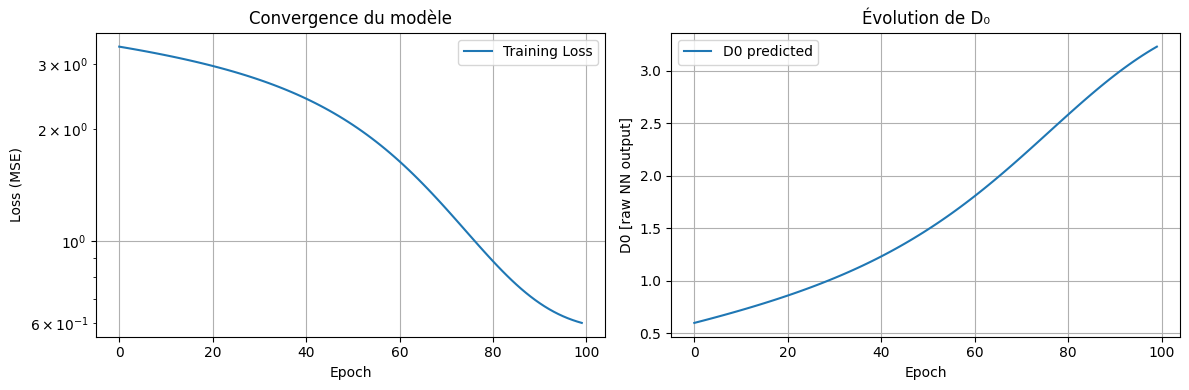

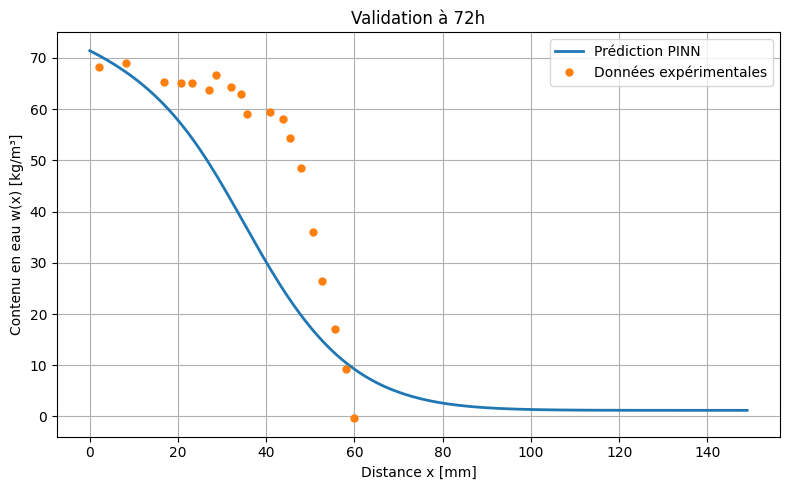

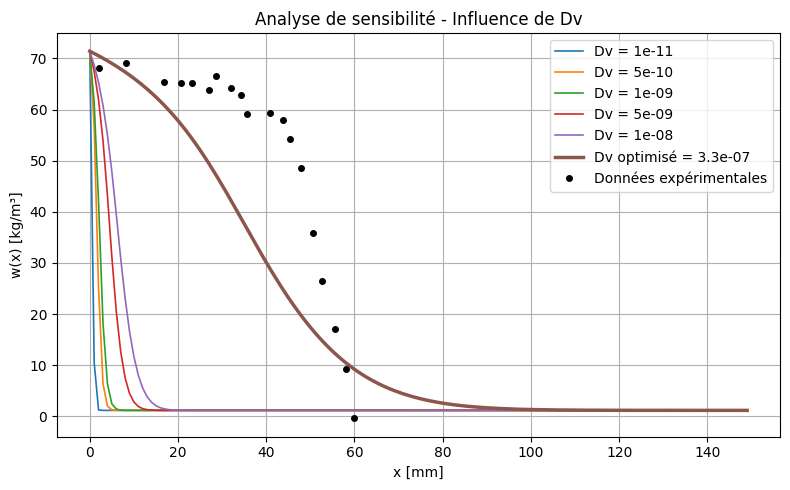


📋 Paramètres optimisés :
✅ Coefficient de diffusion Dv = 3.2947e-07 m²/s
✅ Perte finale (MSE) = 6.0163e-01


In [91]:
# 🔍 1. Dv final cohérent avec training
D0_final = model(normalize(input_tensor))
Dv = tf.squeeze(tf.nn.softplus(D0_final) * 1e-7)  # ✅ même transformation que training

# 🔁 Simulation finale
x_model, w_model = simulate_model_tf(Dv, 0.6, 0.119, 1000.0, 1e-3, 10.0, 72*3600, 150)

# 📈 2. Courbes d’apprentissage
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.semilogy(loss_history, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Convergence du modèle")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(D0_history, label="D0 predicted")
plt.xlabel("Epoch")
plt.ylabel("D0 [raw NN output]")
plt.title("Évolution de D₀")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# 📊 3. Comparaison Prédiction vs Données expérimentales
plt.figure(figsize=(8, 5))
plt.plot(x_model.numpy()*1000, w_model.numpy(), label="Prédiction PINN", lw=2)
plt.plot(x_exp.numpy(), w_exp.numpy(), 'o', label="Données expérimentales", markersize=5)
plt.xlabel("Distance x [mm]")
plt.ylabel("Contenu en eau w(x) [kg/m³]")
plt.title("Validation à 72h")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 📉 4. Analyse de sensibilité
plt.figure(figsize=(8, 5))
Dv_ref = Dv.numpy()
Dv_test_vals = [1e-11, 5e-10, 1e-9, 5e-9, 1e-8, Dv_ref]

for Dv_test in Dv_test_vals:
    x_test, w_test = simulate_model_tf(
        tf.constant(Dv_test, dtype=tf.float32), 0.6, 0.119, 1000.0,
        dx=1e-3, dt=10.0, Tmax=72*3600, Nx=150
    )
    label = f"Dv = {Dv_test:.0e}" if Dv_test != Dv_ref else f"Dv optimisé = {Dv_ref:.1e}"
    lw = 2.5 if Dv_test == Dv_ref else 1.2
    plt.plot(x_test.numpy()*1000, w_test.numpy(), label=label, lw=lw)

plt.plot(x_exp.numpy(), w_exp.numpy(), 'ko', label="Données expérimentales", markersize=4)
plt.xlabel("x [mm]")
plt.ylabel("w(x) [kg/m³]")
plt.title("Analyse de sensibilité - Influence de Dv")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 📋 5. Résumé final
print("\n📋 Paramètres optimisés :")
print(f"✅ Coefficient de diffusion Dv = {Dv.numpy():.4e} m²/s")
print(f"✅ Perte finale (MSE) = {loss_history[-1]:.4e}")


## ⚠️ Debug: Retirer `@tf.function` pour le calcul différentiable

Pour le debugging, retirez `@tf.function` sur les fonctions physiques pour garantir la propagation du gradient.